In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")
df = pd.DataFrame(data)

In [3]:
df.shape

(4340, 8)

In [4]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [6]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(763)

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.describe()

,year,selling_price,km_driven
count,3577.000000,3.577000e+03,3577.000000
mean,2012.962538,4.739125e+05,69250.545709
std,4.251759,5.093018e+05,47579.940016
min,1992.000000,2.000000e+04,1.000000
25%,2010.000000,2.000000e+05,36000.000000
50%,2013.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [10]:
num_cols = ['selling_price', 'km_driven']
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))]
    print(f"Outliers detected in {col}: {len(outliers)}")

Outliers detected in selling_price: 170
Outliers detected in km_driven: 106


In [11]:
current_year = 2026
df['car_age'] = current_year - df['year']

In [12]:
df.drop(columns=['name', 'year', 'owner'], inplace=True)

In [13]:
df = pd.get_dummies(df, columns=['fuel', 'seller_type', 'transmission'], drop_first=True)

In [14]:
print(df.columns.tolist())

['selling_price', 'km_driven', 'car_age', 'fuel_Diesel', 'fuel_Electric', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'transmission_Manual']


In [15]:
X = df.drop(columns=['selling_price'])
y = df['selling_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
models = {
    "Linear Regression": (LinearRegression(), True),
    "Decision Tree": (DecisionTreeRegressor(random_state=42, max_depth=5), False),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=42), False)
}

results = []

for name, (model, requires_scaling) in models.items():
    X_tr = X_train_scaled if requires_scaling else X_train
    X_te = X_test_scaled if requires_scaling else X_test
    
    model.fit(X_tr, y_train)
    preds = model.predict(X_te)
    
    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    
    results.append({
        "Model": name,
        "MAE": round(mae, 4),
        "MSE": round(mse, 4),
        "RMSE": round(rmse, 4),
        "R2 Score": round(r2, 4),
        "Estimator": model,
        "Predictions": preds
    })

In [19]:
results_df = pd.DataFrame(results)[["Model", "MAE", "MSE", "RMSE", "R2 Score"]]
print("\nModel Performance Comparison")
print(results_df.to_string(index=False))

best_idx = results_df["R2 Score"].idxmax()
best_model_name = results_df.loc[best_idx, "Model"]
best_preds = results[best_idx]["Predictions"]
best_model = results[best_idx]["Estimator"]
print(f"\nBest-Performing Model: {best_model_name} (Highest R2: {results_df.loc[best_idx, 'R2 Score']})")


Model Performance Comparison
            Model         MAE          MSE        RMSE  R2 Score
Linear Regression 213654.0684 1.957990e+11 442491.7977    0.3922
    Decision Tree 188643.2176 1.801771e+11 424472.7840    0.4407
    Random Forest 188259.5652 1.732326e+11 416212.2499    0.4622

Best-Performing Model: Random Forest (Highest R2: 0.4622)


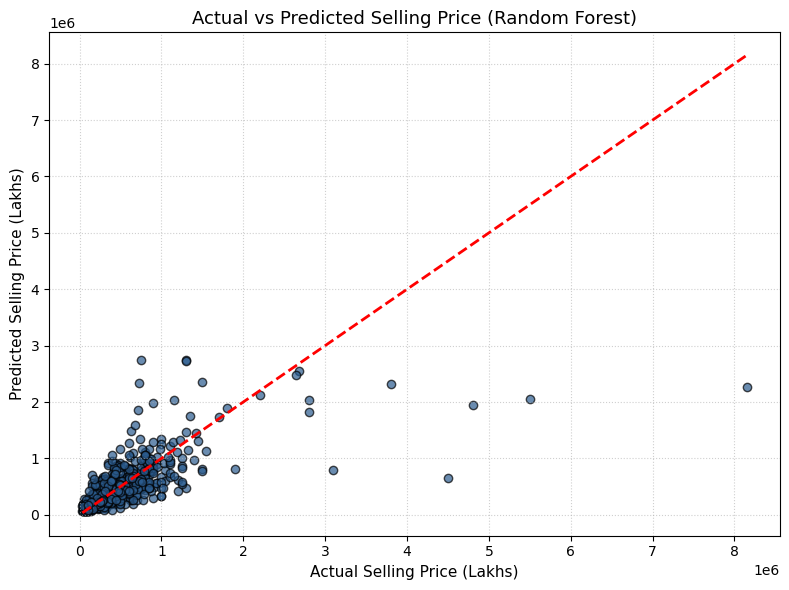

In [20]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_preds, alpha=0.7, edgecolors='k', color='#2b5c8f')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title(f'Actual vs Predicted Selling Price ({best_model_name})', fontsize=13)
plt.xlabel('Actual Selling Price (Lakhs)', fontsize=11)
plt.ylabel('Predicted Selling Price (Lakhs)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


Feature Importances
km_driven                       0.291380
car_age                         0.289335
transmission_Manual             0.259471
fuel_Diesel                     0.075293
fuel_Petrol                     0.044005
seller_type_Individual          0.037330
seller_type_Trustmark Dealer    0.003142
fuel_LPG                        0.000044
fuel_Electric                   0.000000
dtype: float64


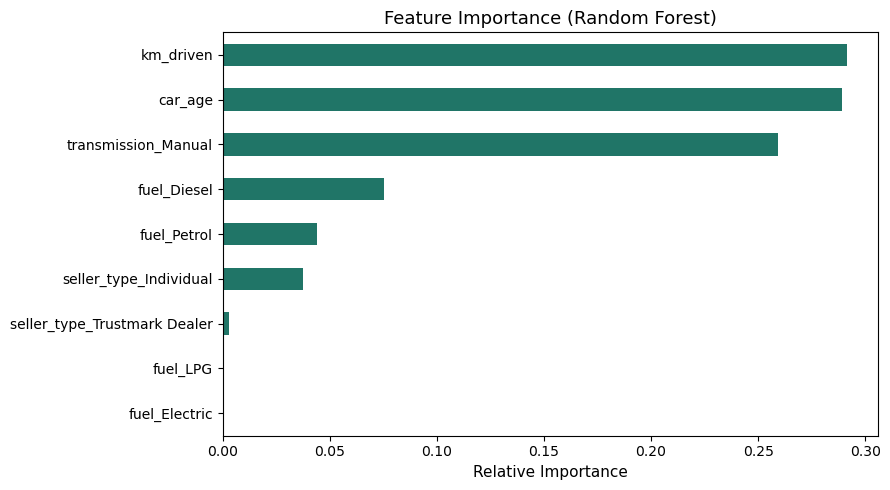

In [21]:
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
    print("\nFeature Importances")
    print(importances)
    
    plt.figure(figsize=(9, 5))
    importances.plot(kind='barh', color='#207567')
    plt.title(f'Feature Importance ({best_model_name})', fontsize=13)
    plt.xlabel('Relative Importance', fontsize=11)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()